[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/shuishen112/neural-networks/blob/main/lectures/06_cnns.ipynb)

# Lecture 6 — Convolutional Neural Networks

**Neural Networks · Master's course**

An MLP treats its input as an unordered vector: if we permuted the 64 pixels of
every digit image in the same fixed way, an MLP would learn equally well. That
is a waste — images have **structure**. Nearby pixels are strongly correlated,
the same pattern (an edge, a stroke end, an eye) can appear anywhere, and
objects are composed hierarchically of parts.

**Convolutional neural networks** (CNNs) build these assumptions into the
architecture. In this lecture we

1. motivate convolution through *locality*, *weight sharing* and *translation equivariance*;
2. implement 2-D convolution from scratch and check it against `F.conv2d`;
3. study padding, stride, channels, receptive fields and pooling;
4. build a LeNet-style CNN for the digits, compare it with an MLP, and look
   inside it (filters, feature maps, robustness to shifts);
5. survey modern architectures — VGG and **ResNet**, whose residual block we implement —
   and the idea of transfer learning.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

torch.manual_seed(0)
rng = np.random.default_rng(0)
plt.rcParams["figure.figsize"] = (5, 4)
plt.rcParams["axes.grid"] = False
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

device: cpu


## 1. Why convolutions?

Consider a modest colour image of $224\times224\times3$ pixels and a first hidden
layer of 1 000 units. A fully connected layer needs $224\cdot224\cdot3\cdot1000
\approx 1.5\times10^8$ weights — for one layer, and it would still have to learn
separately, at every position, what an edge looks like. Three priors fix this:

* **Locality.** A hidden unit looks only at a small patch of the input (its
  *receptive field*), e.g. $3\times3$ pixels. Distant pixels interact only in
  deeper layers.
* **Weight sharing.** The same small set of weights (a *filter* or *kernel*) is
  applied at every position. A detector for a vertical edge is useful everywhere.
* **Translation equivariance.** As a consequence, shifting the input shifts the
  output: $\operatorname{conv}(T_{\boldsymbol\delta}\,x) = T_{\boldsymbol\delta}\operatorname{conv}(x)$,
  where $T_{\boldsymbol\delta}$ translates an image by $\boldsymbol\delta$.
  *Pooling* later turns this into a degree of approximate translation **invariance**.

A convolutional layer with 64 filters of size $3\times3$ on a 3-channel image has
$64\cdot(3\cdot3\cdot3+1) = 1\,792$ parameters, independently of the image size.

In [2]:
H = W = 224
fc_params = H * W * 3 * 1000 + 1000
conv_params = 64 * (3 * 3 * 3) + 64
print(f"fully connected 224x224x3 -> 1000 : {fc_params:>13,d} parameters")
print(f"conv 3 -> 64 channels, 3x3 kernels : {conv_params:>13,d} parameters")
print(f"nn.Conv2d agrees: {sum(p.numel() for p in nn.Conv2d(3, 64, 3).parameters()):,d}")

fully connected 224x224x3 -> 1000 :   150,529,000 parameters
conv 3 -> 64 channels, 3x3 kernels :         1,792 parameters
nn.Conv2d agrees: 1,792


## 2. The 2-D convolution

For a single-channel image $X$ and a kernel $K$ of size $k_h\times k_w$, the
operation used in deep learning is

$$Y[i,j] = \sum_{u=0}^{k_h-1}\sum_{v=0}^{k_w-1} K[u,v]\; X[i+u,\; j+v] + b .$$

Strictly speaking this is a **cross-correlation**: the mathematical convolution
flips the kernel, $Y[i,j] = \sum_{u,v} K[u,v]\,X[i-u, j-v]$. Since the kernel is
learned, the distinction is irrelevant in practice (the network would just learn
the flipped kernel) and every framework implements cross-correlation under the
name "convolution".

**Channels.** Real layers map $C_{in}$ input channels to $C_{out}$ output channels.
Each output channel has its own kernel *spanning all input channels*, so the
weight tensor has shape $(C_{out}, C_{in}, k_h, k_w)$:

$$Y[n, o, i, j] = b_o + \sum_{c=0}^{C_{in}-1}\sum_{u,v} K[o, c, u, v]\; X[n, c,\; i s + u,\; j s + v],$$

where $s$ is the **stride** and $X$ has already been zero-padded by $p$ pixels on
each side. PyTorch uses the layout `(N, C, H, W)`: batch, channels, height, width.

Let us implement this literally, with loops over the output positions and the
sum over $(c, u, v)$ done by `np.einsum`, and compare with `F.conv2d`.

In [3]:
def conv2d_loops(x, w, b=None, stride=1, padding=0):
    """Naive 2-D cross-correlation. x: (N, C_in, H, W), w: (C_out, C_in, kh, kw)."""
    N, C_in, H, W = x.shape
    C_out, _, kh, kw = w.shape
    x = np.pad(x, ((0, 0), (0, 0), (padding, padding), (padding, padding)))
    H_out = (H + 2 * padding - kh) // stride + 1
    W_out = (W + 2 * padding - kw) // stride + 1
    y = np.zeros((N, C_out, H_out, W_out))
    for i in range(H_out):
        for j in range(W_out):
            patch = x[:, :, i * stride:i * stride + kh, j * stride:j * stride + kw]   # (N, C_in, kh, kw)
            y[:, :, i, j] = np.einsum("ncuv,ocuv->no", patch, w)
    if b is not None:
        y += b[None, :, None, None]
    return y

x_np = rng.standard_normal((2, 3, 7, 9))
w_np = rng.standard_normal((4, 3, 3, 3))
b_np = rng.standard_normal(4)
for stride, padding in [(1, 0), (1, 1), (2, 1), (3, 2)]:
    mine = conv2d_loops(x_np, w_np, b_np, stride, padding)
    ref = F.conv2d(torch.from_numpy(x_np), torch.from_numpy(w_np), torch.from_numpy(b_np),
                   stride=stride, padding=padding).numpy()
    print(f"stride {stride}, padding {padding}: output {mine.shape}, "
          f"max |difference| = {np.abs(mine - ref).max():.1e}")
    assert np.allclose(mine, ref)

stride 1, padding 0: output (2, 4, 5, 7), max |difference| = 1.1e-14
stride 1, padding 1: output (2, 4, 7, 9), max |difference| = 1.1e-14
stride 2, padding 1: output (2, 4, 4, 5), max |difference| = 1.1e-14
stride 3, padding 2: output (2, 4, 3, 4), max |difference| = 2.9e-15


And the cross-correlation/convolution relation: correlating with the kernel
flipped in both spatial directions gives the true convolution.

In [4]:
def true_conv_single(x, k):
    """Mathematical ('full flip') convolution of a 2-D array, 'valid' region only."""
    kh, kw = k.shape
    out = np.zeros((x.shape[0] - kh + 1, x.shape[1] - kw + 1))
    for i in range(out.shape[0]):
        for j in range(out.shape[1]):
            for u in range(kh):
                for v in range(kw):
                    out[i, j] += k[u, v] * x[i + kh - 1 - u, j + kw - 1 - v]
    return out

img, k = rng.standard_normal((6, 6)), rng.standard_normal((3, 3))
conv = true_conv_single(img, k)
xcorr_flipped = conv2d_loops(img[None, None], k[::-1, ::-1][None, None])[0, 0]
print("convolution == cross-correlation with flipped kernel:", np.allclose(conv, xcorr_flipped))

convolution == cross-correlation with flipped kernel: True


### 2.1 Filters as feature detectors

Before learning filters, let us apply hand-designed ones. The Sobel kernels
approximate horizontal and vertical derivatives; they respond to edges with a
particular orientation and are blind to flat regions.

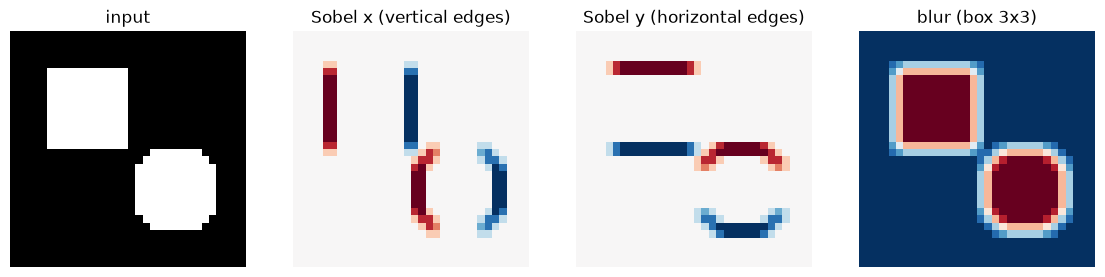

In [5]:
yy, xx = np.mgrid[0:32, 0:32]
scene = ((np.abs(xx - 10) < 6) & (np.abs(yy - 10) < 6)).astype(float)        # a square
scene += ((xx - 22) ** 2 + (yy - 21) ** 2 < 36).astype(float)                # a disc
sobel_x = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], dtype=float)
kernels = {"Sobel x (vertical edges)": sobel_x, "Sobel y (horizontal edges)": sobel_x.T,
           "blur (box 3x3)": np.ones((3, 3)) / 9}

fig, axes = plt.subplots(1, 4, figsize=(14, 3.3))
axes[0].imshow(scene, cmap="gray"); axes[0].set_title("input")
for ax, (name, kern) in zip(axes[1:], kernels.items()):
    out = F.conv2d(torch.tensor(scene)[None, None], torch.tensor(kern)[None, None], padding=1)[0, 0]
    ax.imshow(out.numpy(), cmap="RdBu_r"); ax.set_title(name)
for ax in axes:
    ax.axis("off")
plt.show()

### 2.2 Translation equivariance, numerically

Place a digit on a $16\times16$ canvas, shift it by two pixels, and compare
"convolve then shift" with "shift then convolve". Away from the borders (where
zero padding breaks the symmetry) they agree exactly.

conv(shift(x)) == shift(conv(x)): True


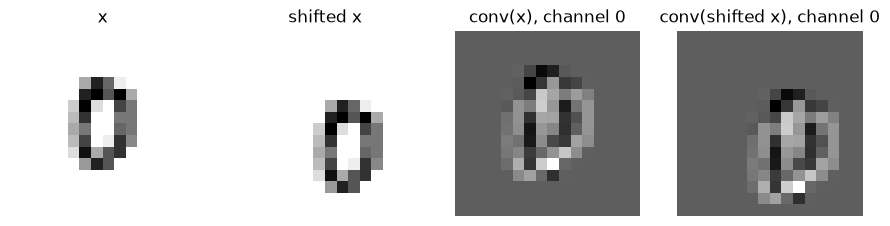

In [6]:
digits = load_digits()
canvas = np.zeros((16, 16), dtype=np.float32)
canvas[4:12, 4:12] = digits.images[0] / 16.0
x_c = torch.from_numpy(canvas)[None, None]                      # (1, 1, 16, 16)
shift = lambda t: torch.roll(t, shifts=(2, 2), dims=(-2, -1))   # exact here: the border is empty

torch.manual_seed(0)
conv_layer = nn.Conv2d(1, 4, kernel_size=3, padding=1)
with torch.no_grad():
    a = shift(conv_layer(x_c))
    b = conv_layer(shift(x_c))
print("conv(shift(x)) == shift(conv(x)):", torch.allclose(a, b, atol=1e-6))

fig, axes = plt.subplots(1, 4, figsize=(11, 3))
for ax, t, title in zip(axes, [x_c, shift(x_c), conv_layer(x_c)[:, :1], conv_layer(shift(x_c))[:, :1]],
                        ["x", "shifted x", "conv(x), channel 0", "conv(shifted x), channel 0"]):
    ax.imshow(t[0, 0].detach().numpy(), cmap="gray_r"); ax.set_title(title); ax.axis("off")
plt.show()

## 3. Padding, stride, output size and receptive field

For input size $n$ (height or width), kernel size $k$, padding $p$ on each side,
stride $s$ and dilation $d$ (the spacing between kernel taps, $d=1$ by default),

$$n_{\text{out}} = \left\lfloor \frac{n + 2p - d(k-1) - 1}{s} \right\rfloor + 1
\;\overset{d=1}{=}\; \left\lfloor \frac{n + 2p - k}{s} \right\rfloor + 1 .$$

* **"valid"** convolution ($p=0$) shrinks the image by $k-1$;
* **"same"** convolution, $p = (k-1)/2$ for odd $k$ and $s=1$, keeps the size;
* **stride** $s>1$ downsamples by a factor $\approx s$.

In [7]:
x = torch.randn(1, 1, 28, 28)
for k, s, p in [(3, 1, 0), (3, 1, 1), (5, 1, 2), (3, 2, 1), (4, 2, 1), (7, 2, 3), (5, 3, 0)]:
    out = nn.Conv2d(1, 1, kernel_size=k, stride=s, padding=p)(x)
    formula = (28 + 2 * p - k) // s + 1
    print(f"k={k}, s={s}, p={p}:  28 -> {out.shape[-1]:2d}   (formula: {formula})")

k=3, s=1, p=0:  28 -> 26   (formula: 26)
k=3, s=1, p=1:  28 -> 28   (formula: 28)
k=5, s=1, p=2:  28 -> 28   (formula: 28)
k=3, s=2, p=1:  28 -> 14   (formula: 14)
k=4, s=2, p=1:  28 -> 14   (formula: 14)
k=7, s=2, p=3:  28 -> 14   (formula: 14)
k=5, s=3, p=0:  28 ->  8   (formula: 8)


**Receptive field.** The receptive field of a unit is the region of the *input*
that can influence it. Stacking layers grows it: with kernel sizes $k_l$ and strides
$s_l$,

$$r_L = 1 + \sum_{l=1}^{L} (k_l - 1)\prod_{i=1}^{l-1} s_i .$$

Two stacked $3\times3$ convolutions see $5\times5$ pixels, three see $7\times7$ —
with fewer parameters ($3\cdot 9C^2$ vs $49C^2$) and more nonlinearities than a single
$7\times7$ layer. Strides and pooling multiply the growth of all later layers.
We can also *measure* a receptive field with autograd: the gradient of one
output unit with respect to the input is non-zero exactly on its receptive field.
(We use average pooling here: max pooling would route the gradient only to the
arg-max of each window and hide part of the receptive field.)

formula : 10
measured: (10, 10)


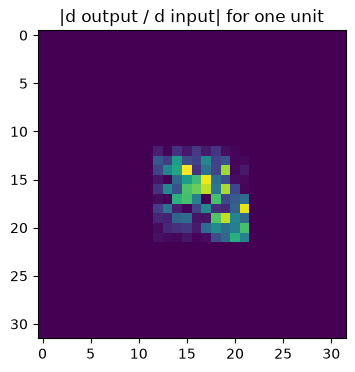

In [8]:
def receptive_field(layers):
    r, jump = 1, 1
    for k, s in layers:
        r += (k - 1) * jump
        jump *= s
    return r

stack = nn.Sequential(nn.Conv2d(1, 1, 3), nn.Conv2d(1, 1, 3), nn.AvgPool2d(2), nn.Conv2d(1, 1, 3))
x = torch.randn(1, 1, 32, 32, requires_grad=True)
out = stack(x)
out[0, 0, out.shape[2] // 2, out.shape[3] // 2].backward()
support = (x.grad[0, 0] != 0)
rows, cols = support.any(1).nonzero(), support.any(0).nonzero()
measured = (rows.max() - rows.min() + 1).item(), (cols.max() - cols.min() + 1).item()
print("formula :", receptive_field([(3, 1), (3, 1), (2, 2), (3, 1)]))
print("measured:", measured)
plt.imshow(x.grad[0, 0].abs().numpy(), cmap="viridis")
plt.title("|d output / d input| for one unit"); plt.show()

## 4. Pooling

A **pooling** layer summarises each local window by a fixed function — its
maximum (`nn.MaxPool2d`) or average (`nn.AvgPool2d`) — independently per channel.
It has no parameters. With a $2\times2$ window and stride 2 it halves the
resolution, which

* reduces computation for later layers and enlarges their receptive field, and
* makes the representation **invariant to small shifts**: the max of a window
  does not change if the strongest activation moves within the window.

Gradient of max pooling: it routes the incoming gradient to the arg-max position
of each window and gives zero to the others (like a ReLU "switch").

**Global average pooling** (`nn.AdaptiveAvgPool2d(1)`) averages each channel over
the whole image, giving a fixed-length vector regardless of input size; most
modern CNNs end with it instead of a large fully connected layer.

In [9]:
x = torch.tensor([[[[1., 3., 2., 0.],
                    [4., 2., 1., 1.],
                    [0., 1., 5., 6.],
                    [2., 2., 7., 1.]]]], requires_grad=True)
mp = F.max_pool2d(x, kernel_size=2)
ap = F.avg_pool2d(x, kernel_size=2)
print("max pool:\n", mp[0, 0].detach())
print("avg pool:\n", ap[0, 0].detach())
mp.sum().backward()
print("gradient of max pool (1 at the arg-max of each window):\n", x.grad[0, 0])

max pool:
 tensor([[4., 2.],
        [2., 7.]])
avg pool:
 tensor([[2.5000, 1.0000],
        [1.2500, 4.7500]])
gradient of max pool (1 at the arg-max of each window):
 tensor([[0., 0., 1., 0.],
        [1., 0., 0., 0.],
        [0., 0., 0., 0.],
        [1., 0., 1., 0.]])


## 5. A CNN for the digits

We now build a small LeNet-style network (LeCun et al., 1998) designed for our
$8\times8$ images: two blocks of "convolution → ReLU → (convolution →) max-pool",
followed by a small classifier.

| layer | output shape | parameters |
|---|---|---|
| input | $1\times8\times8$ | |
| conv $3\times3$, 16, pad 1 + ReLU | $16\times8\times8$ | $16(9+1)=160$ |
| conv $3\times3$, 32, pad 1 + ReLU | $32\times8\times8$ | $32(16\cdot9+1)=4\,640$ |
| max-pool $2\times2$ | $32\times4\times4$ | |
| conv $3\times3$, 64, pad 1 + ReLU | $64\times4\times4$ | $64(32\cdot9+1)=18\,496$ |
| max-pool $2\times2$ | $64\times2\times2$ | |
| flatten, linear 256 → 64 + ReLU, linear 64 → 10 | 10 | $16\,448 + 650$ |

We use the same data splits as in Lecture 4, with images in `(N, 1, 8, 8)` layout.

In [10]:
X_all = (digits.data / 16.0).astype(np.float32)
y_all = digits.target.astype(np.int64)
X_trval, X_test, y_trval, y_test = train_test_split(X_all, y_all, test_size=0.2, random_state=0, stratify=y_all)
X_train, X_val, y_train, y_val = train_test_split(X_trval, y_trval, test_size=0.2, random_state=0, stratify=y_trval)

def image_ds(X, y):
    return TensorDataset(torch.from_numpy(X).reshape(-1, 1, 8, 8), torch.from_numpy(y))

train_ds, val_ds, test_ds = image_ds(X_train, y_train), image_ds(X_val, y_val), image_ds(X_test, y_test)
val_loader = DataLoader(val_ds, batch_size=512)
test_loader = DataLoader(test_ds, batch_size=512)
print("train", len(train_ds), "| val", len(val_ds), "| test", len(test_ds), "| one image:", tuple(train_ds[0][0].shape))

train 1149 | val 288 | test 360 | one image: (1, 8, 8)


In [11]:
class DigitCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1), nn.ReLU(),
            nn.Conv2d(16, 32, kernel_size=3, padding=1), nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1), nn.ReLU(),
            nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),                      # (N, 64, 2, 2) -> (N, 256)
            nn.Linear(64 * 2 * 2, 64), nn.ReLU(),
            nn.Linear(64, 10),
        )

    def forward(self, x):
        return self.classifier(self.features(x))


class FlatMLP(nn.Module):
    """MLP baseline that accepts the same (N, 1, 8, 8) images."""
    def __init__(self, hidden=128):
        super().__init__()
        self.net = nn.Sequential(nn.Flatten(), nn.Linear(64, hidden), nn.ReLU(),
                                 nn.Linear(hidden, hidden), nn.ReLU(), nn.Linear(hidden, 10))

    def forward(self, x):
        return self.net(x)


def n_params(model):
    return sum(p.numel() for p in model.parameters())

x = torch.randn(5, 1, 8, 8)
cnn = DigitCNN()
for layer in cnn.features:
    x = layer(x)
    print(f"{layer.__class__.__name__:10s} -> {tuple(x.shape)}")
print("CNN parameters:", n_params(cnn), "| MLP parameters:", n_params(FlatMLP()))

Conv2d     -> (5, 16, 8, 8)
ReLU       -> (5, 16, 8, 8)
Conv2d     -> (5, 32, 8, 8)
ReLU       -> (5, 32, 8, 8)
MaxPool2d  -> (5, 32, 4, 4)
Conv2d     -> (5, 64, 4, 4)
ReLU       -> (5, 64, 4, 4)
MaxPool2d  -> (5, 64, 2, 2)
CNN parameters: 40394 | MLP parameters: 26122


The training loop is the one from Lecture 4.

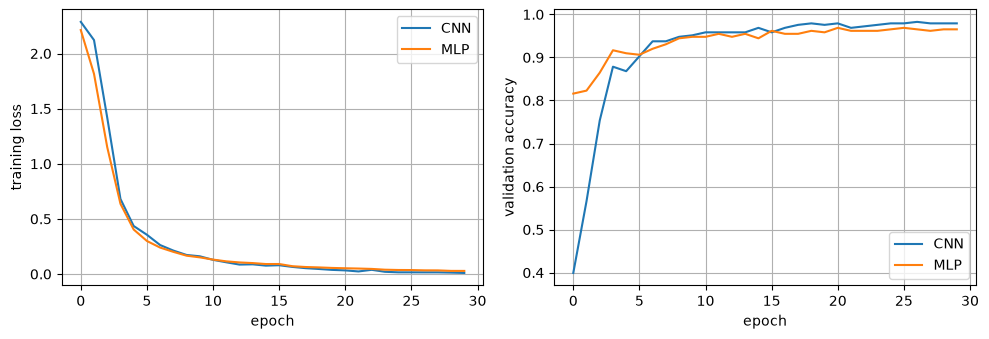

test accuracy: CNN 0.967 (40394 params) | MLP 0.967 (26122 params)


In [12]:
@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    total, correct, n = 0.0, 0, 0
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        logits = model(xb)
        total += F.cross_entropy(logits, yb, reduction="sum").item()
        correct += (logits.argmax(1) == yb).sum().item()
        n += len(yb)
    return total / n, correct / n


def fit(model, train_ds, n_epochs=30, lr=1e-3, batch_size=64, weight_decay=0.0, seed=0):
    model.to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True,
                        generator=torch.Generator().manual_seed(seed))
    hist = {"train_loss": [], "val_acc": []}
    for epoch in range(n_epochs):
        model.train()
        total, n = 0.0, 0
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            loss = F.cross_entropy(model(xb), yb)
            opt.zero_grad(); loss.backward(); opt.step()
            total += loss.item() * len(yb); n += len(yb)
        hist["train_loss"].append(total / n)
        hist["val_acc"].append(evaluate(model, val_loader)[1])
    return hist

torch.manual_seed(0)
cnn = DigitCNN()
hist_cnn = fit(cnn, train_ds)
torch.manual_seed(0)
mlp = FlatMLP()
hist_mlp = fit(mlp, train_ds)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for name, h in [("CNN", hist_cnn), ("MLP", hist_mlp)]:
    axes[0].plot(h["train_loss"], label=name); axes[1].plot(h["val_acc"], label=name)
axes[0].set_ylabel("training loss"); axes[1].set_ylabel("validation accuracy")
for ax in axes:
    ax.set_xlabel("epoch"); ax.legend(); ax.grid(True)
plt.tight_layout(); plt.show()

acc_cnn = evaluate(cnn, test_loader)[1]
acc_mlp = evaluate(mlp, test_loader)[1]
print(f"test accuracy: CNN {acc_cnn:.3f} ({n_params(cnn)} params) | MLP {acc_mlp:.3f} ({n_params(mlp)} params)")
assert acc_cnn >= 0.90

On these tiny, centred and size-normalised $8\times8$ digits an MLP is already
very good, so the gap is small. The advantages of CNNs grow with image size and
variability; on MNIST ($28\times28$) a small CNN roughly halves the error of an MLP,
and on natural images the difference is dramatic.

### 5.1 Looking inside: filters and feature maps

The 16 first-layer filters are $3\times3$ patches; on $8\times8$ images they cannot
be very elaborate, but many of them look like oriented edge or stroke detectors.
The **feature maps** show where each filter responds in a given image.

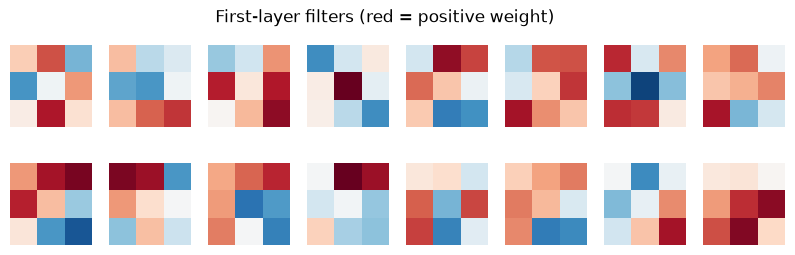

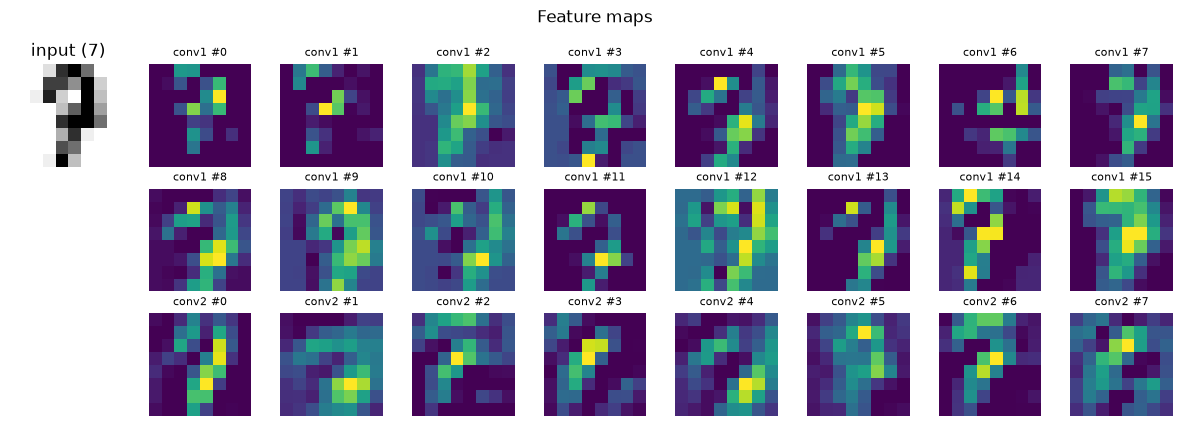

In [13]:
w1 = cnn.features[0].weight.detach().cpu()           # (16, 1, 3, 3)
fig, axes = plt.subplots(2, 8, figsize=(10, 2.8))
lim = w1.abs().max().item()
for k, ax in enumerate(axes.flat):
    ax.imshow(w1[k, 0].numpy(), cmap="RdBu_r", vmin=-lim, vmax=lim); ax.axis("off")
plt.suptitle("First-layer filters (red = positive weight)"); plt.show()

x0 = test_ds[0][0][None].to(device)                   # (1, 1, 8, 8)
cnn.eval()
with torch.no_grad():
    maps1 = cnn.features[:2](x0)[0].cpu()            # after conv1 + ReLU: (16, 8, 8)
    maps2 = cnn.features[:4](x0)[0].cpu()            # after conv2 + ReLU: (32, 8, 8)
fig, axes = plt.subplots(3, 9, figsize=(12, 4.3))
axes[0, 0].imshow(x0[0, 0].cpu().numpy(), cmap="gray_r"); axes[0, 0].set_title(f"input ({test_ds[0][1].item()})")
for k in range(8):
    axes[0, k + 1].imshow(maps1[k].numpy(), cmap="viridis"); axes[0, k + 1].set_title(f"conv1 #{k}", fontsize=8)
    axes[1, k + 1].imshow(maps1[k + 8].numpy(), cmap="viridis"); axes[1, k + 1].set_title(f"conv1 #{k + 8}", fontsize=8)
    axes[2, k + 1].imshow(maps2[k].numpy(), cmap="viridis"); axes[2, k + 1].set_title(f"conv2 #{k}", fontsize=8)
for ax in axes.flat:
    ax.axis("off")
plt.suptitle("Feature maps"); plt.tight_layout(); plt.show()

### 5.2 Robustness to translations

The MLP has no notion that pixel $(3,4)$ is next to pixel $(3,5)$; after a shift,
a digit activates a completely different set of input weights. The CNN's
convolutions are equivariant and its pooling gives some local invariance. Let
us shift the test images by $\delta$ pixels horizontally (filling with zeros) and
compare. Neither model was trained on shifted digits.

CNN 0.261 0.781 0.967 0.717 0.292
MLP 0.183 0.453 0.967 0.444 0.119


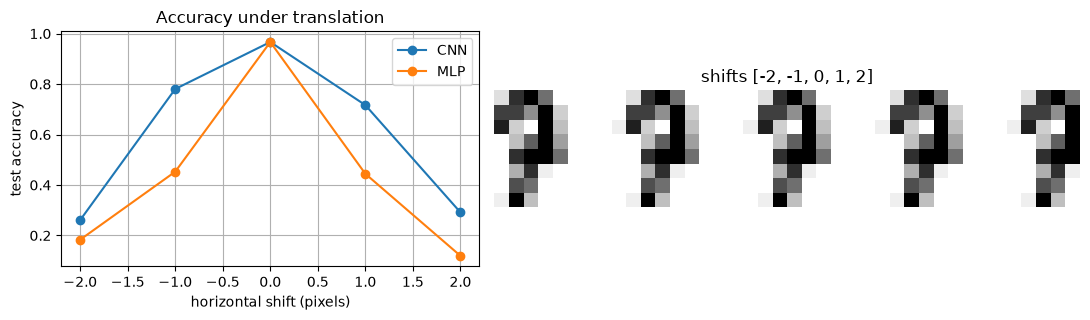

In [14]:
def shift_images(X, dx=0, dy=0):
    """Shift a batch (N, 1, H, W) by (dy, dx) pixels, filling with zeros."""
    N, C, H, W = X.shape
    p = max(abs(dx), abs(dy))
    Xp = F.pad(X, (p, p, p, p))
    return Xp[:, :, p - dy:p - dy + H, p - dx:p - dx + W]

X_test_t = torch.from_numpy(X_test).reshape(-1, 1, 8, 8)
y_test_t = torch.from_numpy(y_test)
shifts = [-2, -1, 0, 1, 2]
rob = {"CNN": [], "MLP": []}
for d in shifts:
    loader = DataLoader(TensorDataset(shift_images(X_test_t, dx=d), y_test_t), batch_size=512)
    rob["CNN"].append(evaluate(cnn, loader)[1])
    rob["MLP"].append(evaluate(mlp, loader)[1])
for name, accs in rob.items():
    print(name, " ".join(f"{a:.3f}" for a in accs))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.3), gridspec_kw={"width_ratios": [1, 1.4]})
for name, accs in rob.items():
    axes[0].plot(shifts, accs, "o-", label=name)
axes[0].set_xlabel("horizontal shift (pixels)"); axes[0].set_ylabel("test accuracy")
axes[0].legend(); axes[0].grid(True); axes[0].set_title("Accuracy under translation")
axes[1].imshow(torch.cat([shift_images(X_test_t[:1], dx=d)[0, 0] for d in shifts], dim=1).numpy(), cmap="gray_r")
axes[1].set_title("shifts " + str(shifts)); axes[1].axis("off")
plt.tight_layout(); plt.show()

Both models suffer — on an $8\times8$ image a 2-pixel shift moves the digit by a
quarter of its width and pushes part of it off the canvas — but the CNN typically
degrades more gracefully. Remember that equivariance holds for the convolutions
only; the final flatten + linear layer is position-specific, and a stride-2 pooling
layer is only invariant to shifts that keep the maximum inside its window. In
practice robust invariance is obtained by combining the architecture with
**data augmentation** (Lecture 5). Replacing the flatten by global average pooling
makes the network more shift-tolerant still.

## 6. Modern architectures

**LeNet-5** (1998) → **AlexNet** (2012: ReLU, dropout, GPUs, ImageNet) →
**VGG** (2014) → **GoogLeNet/Inception** (2014) → **ResNet** (2015) → … →
ConvNeXt (2022), and Vision Transformers (Lecture 8).

**VGG** (Simonyan & Zisserman, 2014) showed that a very regular design works:
only $3\times3$ convolutions (stride 1, padding 1) in blocks, each block followed by a
$2\times2$ max-pool, doubling the number of channels whenever the resolution halves
(64 → 128 → 256 → 512). Spatial resolution is traded for depth of representation.

**The degradation problem.** Simply stacking more layers eventually makes even
the *training* error worse — not because of overfitting, but because very deep
plain networks are hard to optimise. **Residual networks** (He et al., 2016) let each
block learn a *correction* to the identity:

$$\mathbf y = \operatorname{ReLU}\big(\mathbf x + \mathcal F(\mathbf x)\big), \qquad
\frac{\partial \mathbf y}{\partial \mathbf x} \propto I + \frac{\partial\mathcal F}{\partial\mathbf x}.$$

The identity *skip connection* gives gradients a direct path to early layers (the
Jacobian is the identity plus a correction rather than a product of many small
matrices), and a block can easily represent "do nothing" by setting
$\mathcal F\approx 0$. In the "basic block" of ResNet-18/34, $\mathcal F$ is
conv–BN–ReLU–conv–BN; when the block changes the resolution or the number of
channels, the shortcut is a $1\times1$ convolution with the same stride (a
*projection shortcut*). `nn.BatchNorm2d` normalises each channel over the batch
**and** all spatial positions.

In [15]:
class ResidualBlock(nn.Module):
    def __init__(self, c_in, c_out, stride=1):
        super().__init__()
        self.conv1 = nn.Conv2d(c_in, c_out, 3, stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(c_out)
        self.conv2 = nn.Conv2d(c_out, c_out, 3, stride=1, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(c_out)
        if stride != 1 or c_in != c_out:
            self.shortcut = nn.Sequential(nn.Conv2d(c_in, c_out, 1, stride=stride, bias=False),
                                          nn.BatchNorm2d(c_out))
        else:
            self.shortcut = nn.Identity()

    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        return F.relu(out + self.shortcut(x))


class TinyResNet(nn.Module):
    def __init__(self, width=16, n_classes=10):
        super().__init__()
        self.stem = nn.Sequential(nn.Conv2d(1, width, 3, padding=1, bias=False),
                                  nn.BatchNorm2d(width), nn.ReLU())
        self.blocks = nn.Sequential(
            ResidualBlock(width, width),               # 8x8
            ResidualBlock(width, 2 * width, stride=2), # 4x4
            ResidualBlock(2 * width, 4 * width, stride=2),  # 2x2
        )
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(4 * width, n_classes))

    def forward(self, x):
        return self.head(self.blocks(self.stem(x)))

x = torch.randn(4, 1, 8, 8)
print("block, same shape :", tuple(ResidualBlock(16, 16)(torch.randn(4, 16, 8, 8)).shape))
print("block, downsample :", tuple(ResidualBlock(16, 32, stride=2)(torch.randn(4, 16, 8, 8)).shape))
torch.manual_seed(0)
resnet = TinyResNet()
print("TinyResNet output:", tuple(resnet(x).shape), "| parameters:", n_params(resnet))

block, same shape : (4, 16, 8, 8)
block, downsample : (4, 32, 4, 4)
TinyResNet output: (4, 10) | parameters: 77754


In [16]:
torch.manual_seed(0)
resnet = TinyResNet()
hist_res = fit(resnet, train_ds, n_epochs=20)
acc_res = evaluate(resnet, test_loader)[1]
print(f"TinyResNet test accuracy: {acc_res:.3f}")

TinyResNet test accuracy: 0.986


Why skip connections help optimisation can be seen directly in the gradients.
Below we build two deep stacks of 20 blocks — plain (`y = ReLU(F(x))`) and residual
(`y = ReLU(x + F(x))`), without batch norm — and compare the gradient norm reaching
the first layer at initialisation.

In [17]:
class PlainOrResidual(nn.Module):
    def __init__(self, c, residual):
        super().__init__()
        self.conv1 = nn.Conv2d(c, c, 3, padding=1)
        self.conv2 = nn.Conv2d(c, c, 3, padding=1)
        self.residual = residual

    def forward(self, x):
        out = self.conv2(F.relu(self.conv1(x)))
        return F.relu(x + out) if self.residual else F.relu(out)

for residual in (False, True):
    torch.manual_seed(0)
    net = nn.Sequential(nn.Conv2d(1, 16, 3, padding=1),
                        *[PlainOrResidual(16, residual) for _ in range(20)],
                        nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(16, 10))
    xb, yb = train_ds[:64]
    F.cross_entropy(net(xb), yb).backward()
    g_first = net[0].weight.grad.norm().item()
    g_last = net[-1].weight.grad.norm().item()
    print(f"{'residual' if residual else 'plain   '}: |grad| first layer {g_first:.2e}, last layer {g_last:.2e}")

plain   : |grad| first layer 4.51e-19, last layer 2.41e-02
residual: |grad| first layer 2.43e-02, last layer 1.73e-01


In the plain stack the gradient reaching the first layer is many orders of
magnitude smaller than at the last layer — the vanishing-gradient problem of
Lecture 3. With skip connections it survives. Together with batch normalisation,
this is what made networks with 100+ layers trainable.

### Transfer learning

Features learned on a large dataset (typically ImageNet, 1.3 M images) are
remarkably general: early layers detect edges, colours and textures, later layers
object parts. For a new task with little data, it is almost always better to start
from such a **pre-trained** network than from random weights:

* **feature extraction:** freeze the pre-trained backbone (`requires_grad_(False)`)
  and train only a new final layer;
* **fine-tuning:** replace the final layer and continue training all (or the upper)
  layers with a small learning rate.

With `torchvision` this takes a few lines (it downloads weights, so we do not run it here):

```python
import torchvision
model = torchvision.models.resnet18(weights=torchvision.models.ResNet18_Weights.DEFAULT)
for p in model.parameters():
    p.requires_grad_(False)                       # freeze the backbone
model.fc = nn.Linear(model.fc.in_features, n_classes)   # new, trainable head
optimizer = torch.optim.AdamW(model.fc.parameters(), lr=1e-3)
```

Pre-trained models expect inputs normalised like their training data (e.g. the
ImageNet channel means and standard deviations) and images of a sensible size.

## 7. Optional: Fashion-MNIST

If you have internet access (e.g. on Colab), set `USE_FASHION_MNIST = True` to
train a slightly larger CNN on Fashion-MNIST: $28\times28$ grey-scale images of
ten kinds of clothing (Xiao et al., 2017). It downloads about 30 MB via
`torchvision`; a few epochs take a couple of minutes on a CPU (seconds on a GPU).
By default this cell does nothing.

In [18]:
USE_FASHION_MNIST = False

if USE_FASHION_MNIST:
    import torchvision
    from torchvision import transforms

    tfm = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.286,), (0.353,))])
    fm_train = torchvision.datasets.FashionMNIST("data", train=True, download=True, transform=tfm)
    fm_test = torchvision.datasets.FashionMNIST("data", train=False, download=True, transform=tfm)
    fm_train_loader = DataLoader(fm_train, batch_size=128, shuffle=True)
    fm_test_loader = DataLoader(fm_test, batch_size=512)

    fm_model = nn.Sequential(
        nn.Conv2d(1, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),   # 14x14
        nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2),  # 7x7
        nn.Conv2d(64, 128, 3, padding=1), nn.BatchNorm2d(128), nn.ReLU(),
        nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(128, 10),
    ).to(device)
    fm_opt = torch.optim.AdamW(fm_model.parameters(), lr=2e-3)
    for epoch in range(3):
        fm_model.train()
        for xb, yb in fm_train_loader:
            xb, yb = xb.to(device), yb.to(device)
            loss = F.cross_entropy(fm_model(xb), yb)
            fm_opt.zero_grad(); loss.backward(); fm_opt.step()
        print(f"epoch {epoch + 1}: Fashion-MNIST test accuracy {evaluate(fm_model, fm_test_loader)[1]:.3f}")
else:
    print("Skipping Fashion-MNIST (set USE_FASHION_MNIST = True to run it).")

Skipping Fashion-MNIST (set USE_FASHION_MNIST = True to run it).


## Summary

* A convolutional layer applies the same small filter at every position:
  **local** connectivity, **shared** weights, **translation-equivariant** output.
  Weight tensor shape $(C_{out}, C_{in}, k_h, k_w)$; data layout $(N, C, H, W)$.
* Output size: $\lfloor (n + 2p - k)/s\rfloor + 1$. Receptive field:
  $r_L = 1 + \sum_l (k_l-1)\prod_{i<l}s_i$.
* Pooling downsamples and adds local shift invariance; global average pooling
  makes the head independent of the input size.
* Typical design: blocks of $3\times3$ convolutions + normalisation + ReLU,
  downsampling while increasing the number of channels, global pooling, linear head.
* Residual connections $\mathbf y = \mathbf x + \mathcal F(\mathbf x)$ keep gradients
  flowing and make very deep networks trainable.
* For small datasets, start from a pre-trained network (transfer learning).

**Further reading.**
Goodfellow, Bengio & Courville, *Deep Learning*, ch. 9;
Dumoulin & Visin, *A Guide to Convolution Arithmetic for Deep Learning*, 2016;
LeCun et al., *Gradient-Based Learning Applied to Document Recognition*, Proc. IEEE 1998;
Simonyan & Zisserman, *Very Deep Convolutional Networks for Large-Scale Image Recognition*, ICLR 2015;
He et al., *Deep Residual Learning for Image Recognition*, CVPR 2016;
Zhang et al., *Dive into Deep Learning*, ch. 7–8;
Stanford CS231n notes on convolutional networks (cs231n.github.io).